# آمار توصیفی داده‌های NBA

در این نوت‌بوک، سه سؤال بخش آمار توصیفی پروژه را با استفاده از فایل‌های پاک‌سازی‌شده و مهندسی‌شده بررسی می‌کنم.

**فایل‌های استفاده‌شده**
- `micheal_jordan_trophy_cleaned_and_engineered.csv`: اطلاعات مربوط به فهرست و رأی‌های جایزه
- `per_game_pss_cleaned_and_engineered.csv`: آمار بازیکنان در هر فصل
- `players_cleaned_and_engineered.csv`: اطلاعات بازیکنان، از جمله قد
- `rosters_cleaned_and_engineered.csv`: اطلاعات ترکیب تیم‌ها و سابقه بازیکنان

فصل‌ها از ۲۰۱۹–۲۰۲۰ تا ۲۰۲۳–۲۰۲۴ هستند. در فایل‌ها، فصل با سال پایان آن ذخیره شده؛ برای مثال، مقدار `2020` به فصل ۲۰۱۹–۲۰۲۰ اشاره دارد.

در صورت پروژه، معیار دقیق انتخاب «۵۰ بازیکن برتر» و «۱۵ بازیکن برتر» مشخص نشده است. برای اینکه بتوانم تحلیل را انجام دهم، بازیکنان را بر اساس میانگین امتیاز در هر بازی (`PTS`) مرتب کرده‌ام. این فرض را در تفسیر نتایج هم در نظر می‌گیرم.

برای بازیکنانی که در طول یک فصل برای بیش از یک تیم بازی کرده‌اند، ردیف تجمیعی همان فصل را انتخاب می‌کنم تا هر بازیکن در آن فصل فقط یک بار شمرده شود.

## ۱. بارگذاری فایل‌ها و بررسی اولیه

In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(".")
mjt = pd.read_csv(DATA_DIR / "micheal_jordan_trophy_cleaned_and_engineered.csv")
per_game = pd.read_csv(DATA_DIR / "per_game_pss_cleaned_and_engineered.csv")
players = pd.read_csv(DATA_DIR / "players_cleaned_and_engineered.csv")
rosters = pd.read_csv(DATA_DIR / "rosters_cleaned_and_engineered.csv")
SEASONS = [2020, 2021, 2022, 2023, 2024]

for name, df in [("MJT",mjt),("Per-game",per_game),("Players",players),("Rosters",rosters)]:
    print(name, "shape:", df.shape)
print("MJT rows in selected seasons:", mjt[mjt["Season"].isin(SEASONS)].shape[0])


MJT shape: (739, 30)
Per-game shape: (25671, 38)
Players shape: (5416, 21)
Rosters shape: (21435, 24)
MJT rows in selected seasons: 61


## ۲. اول: مقایسه توزیع قد بازیکنان

In [15]:
mjt5 = mjt[mjt["Season"].isin(SEASONS)].copy()
pg5 = per_game[per_game["Season"].isin(SEASONS)].copy()
pg5["Is_Multi_Team_Aggregate"] = pd.to_numeric(pg5["Is_Multi_Team_Aggregate"], errors="coerce").fillna(0).astype(int)

unique = []
for (season, player), g in pg5.groupby(["Season", "Player"], dropna=False):
    agg = g[g["Is_Multi_Team_Aggregate"].eq(1)]
    chosen = agg.sort_values("PTS", ascending=False).iloc[0] if len(agg) else g.sort_values("PTS", ascending=False).iloc[0]
    unique.append(chosen)
pg_unique = pd.DataFrame(unique).reset_index(drop=True)

height_lookup = players[["Player","Ht_CM"]].drop_duplicates("Player")
mjt5 = mjt5.merge(height_lookup, on="Player", how="left")
pg_unique = pg_unique.merge(height_lookup.rename(columns={"Ht_CM":"Height_CM"}), on="Player", how="left")
top50 = pg_unique.sort_values(["Season","PTS"], ascending=[True,False]).groupby("Season").head(50).copy()

def descriptive_stats(x):
    x = pd.to_numeric(x, errors="coerce").dropna()
    return pd.Series({"N":x.count(),"Mean":x.mean(),"Median":x.median(),"Std":x.std(),
                      "Min":x.min(),"Q1":x.quantile(.25),"Q3":x.quantile(.75),"Max":x.max()})

height_summary = pd.DataFrame({
    "MJT vote recipients": descriptive_stats(mjt5["Ht_CM"]),
    "Top 50 by PTS/game each season": descriptive_stats(top50["Height_CM"])
}).T
display(height_summary.round(2))
display(top50.groupby("Season").size().rename("Selected players").to_frame())


,N,Mean,Median,Std,Min,Q1,Q3,Max
MJT vote recipients,61.0,200.70,203.20,9.45,182.88,193.04,210.82,215.90
Top 50 by PTS/game each season,250.0,198.75,198.12,8.54,182.88,193.04,203.20,223.52


,Selected players
Season,
2020,50
2021,50
2022,50
2023,50
2024,50


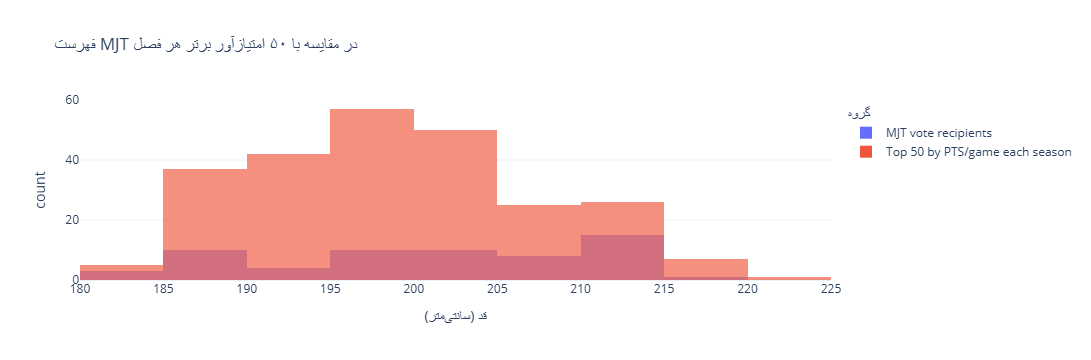

In [16]:
import plotly.express as px

height_plot_data = pd.concat([
    mjt5[["Ht_CM"]].rename(columns={"Ht_CM":"Height_CM"}).assign(Group="MJT vote recipients"),
    top50[["Height_CM"]].assign(Group="Top 50 by PTS/game each season")
], ignore_index=True).dropna(subset=["Height_CM"])

fig_height = px.histogram(
    height_plot_data, x="Height_CM", color="Group", barmode="overlay",
    opacity=0.65, nbins=14,
    labels={"Height_CM":"قد (سانتی‌متر)", "count":"تعداد رکوردها", "Group":"گروه"},
    title=" فهرست MJT در مقایسه با ۵۰ امتیازآور برتر هر فصل"
)
fig_height.update_layout(template="plotly_white", legend_title_text="گروه")
fig_height.show()


**برداشت از نتایج:** میانگین و میانه قد در دو گروه را می‌توان با هم مقایسه کرد تا ببینیم توزیع قد آن‌ها چه تفاوتی دارد. در این محاسبه، هر ردیف نماینده یک بازیکن در یک فصل است؛ بنابراین اگر بازیکنی در چند فصل حضور داشته باشد، در هر فصل جداگانه حساب می‌شود. این مقایسه به‌تنهایی نشان نمی‌دهد که قد بیشتر باعث عملکرد بهتر یا انتخاب برای جایزه شده است.

## ۳. دوم: تجربه و قد بازیکنان تیم‌های قهرمان

In [17]:
champion_info = {2023: ("Denver Nuggets", "DEN"), 2024: ("Boston Celtics", "BOS")}
champion_groups, top15_groups = [], []
for season, (team_name, team_code) in champion_info.items():
    season_stats = pg_unique[pg_unique["Season"].eq(season)].copy()
    roster = rosters[(rosters["Season"].eq(season)) & (rosters["Team"].eq(team_code))].copy()
    active = roster[roster["Player"].isin(set(season_stats["Player"]))].copy()
    active = active.merge(season_stats[["Player","PTS","G"]], on="Player", how="left", suffixes=("_roster","_stats"))
    active["Height_CM"] = active["Ht_CM"]
    active["Season"] = season
    active["Group"] = f"{team_name} active players"
    champion_groups.append(active)

    top15 = season_stats.sort_values("PTS", ascending=False).head(15).copy()
    exp = roster[["Player","Exp_Numeric","Ht_CM"]].drop_duplicates("Player").rename(columns={"Exp_Numeric":"Experience_Years","Ht_CM":"Roster_Height_CM"})
    top15 = top15.merge(exp, on="Player", how="left")
    top15["Height_CM"] = top15["Roster_Height_CM"].combine_first(top15["Height_CM"])
    top15["Season"] = season
    top15["Group"] = "Top 15 by PTS/game"
    top15_groups.append(top15)

champ_df = pd.concat(champion_groups, ignore_index=True)
top15_df = pd.concat(top15_groups, ignore_index=True)
rows = []
for season, (team_name, _) in champion_info.items():
    for group, df in [(f"{team_name} active players",champ_df[champ_df["Season"].eq(season)]),
                      ("Top 15 by PTS/game",top15_df[top15_df["Season"].eq(season)])]:
        for metric, col in [("Experience (years)","Exp_Numeric" if "Exp_Numeric" in df.columns else "Experience_Years"),
                            ("Height (cm)","Height_CM")]:
            if col in df:
                rows.append({"Season":season,"Group":group,"Metric":metric,**descriptive_stats(df[col]).to_dict()})
comparison_summary = pd.DataFrame(rows)
display(comparison_summary.round(2))


,Season,Group,Metric,N,Mean,Median,Std,Min,Q1,Q3,Max
0,2023,Denver Nuggets active players,Experience (years),18.0,5.61,4.50,4.74,0.00,2.25,8.75,14.00
1,2023,Denver Nuggets active players,Height (cm),18.0,199.53,201.93,8.28,182.88,193.68,205.10,210.82
2,2023,Top 15 by PTS/game,Experience (years),0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023,Top 15 by PTS/game,Height (cm),15.0,197.78,198.12,9.59,187.96,187.96,204.47,213.36
4,2024,Boston Celtics active players,Experience (years),19.0,4.68,3.00,4.26,0.00,2.00,6.00,16.00
5,2024,Boston Celtics active players,Height (cm),19.0,200.66,200.66,8.80,185.42,195.58,203.20,218.44
6,2024,Top 15 by PTS/game,Experience (years),1.0,6.00,6.00,NaN,6.00,6.00,6.00,6.00
7,2024,Top 15 by PTS/game,Height (cm),15.0,197.95,195.58,9.91,187.96,187.96,207.01,213.36


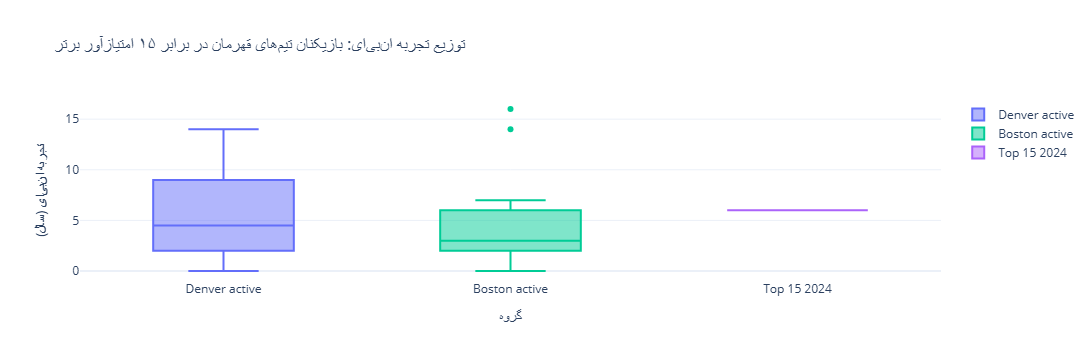

In [18]:
import plotly.graph_objects as go

labels = ["Denver active", "Top 15 2023", "Boston active", "Top 15 2024"]
exp_data = [
    pd.to_numeric(champ_df[champ_df["Season"].eq(2023)]["Exp_Numeric"], errors="coerce").dropna(),
    pd.to_numeric(top15_df[top15_df["Season"].eq(2023)]["Experience_Years"], errors="coerce").dropna(),
    pd.to_numeric(champ_df[champ_df["Season"].eq(2024)]["Exp_Numeric"], errors="coerce").dropna(),
    pd.to_numeric(top15_df[top15_df["Season"].eq(2024)]["Experience_Years"], errors="coerce").dropna()
]

fig_exp = go.Figure()
for label, values in zip(labels, exp_data):
    fig_exp.add_trace(go.Box(y=values, name=label, boxpoints="outliers"))
fig_exp.update_layout(
    title="توزیع تجربه ان‌بی‌ای: بازیکنان تیم‌های قهرمان در برابر ۱۵ امتیازآور برتر",
    yaxis_title="تجربه ان‌بی‌ای (سال)", xaxis_title="گروه", template="plotly_white"
)
fig_exp.show()


**برداشت از نتایج:** در این بخش، تجربه و قد بازیکنان فعال تیم قهرمان را با ۱۵ بازیکنی مقایسه می‌کنیم که در همان فصل میانگین امتیاز بالاتری داشته‌اند. نتایج نشان می‌دهد که این دو گروه از نظر تجربه و قد چه تفاوت‌هایی دارند؛ اما با بررسی فقط دو فصل نمی‌توان گفت این ویژگی‌ها علت قهرمانی بوده‌اند.

## ۴.  سوم: انتخاب سه بازیکن در پست Point Guard

In [19]:
mjt_pos = mjt5[["Season","Player","Share","Rank_Numeric"]].merge(
    pg_unique[["Season","Player","Pos","PTS","AST","TRB"]], on=["Season","Player"], how="left")
pg_mjt = mjt_pos[mjt_pos["Pos"].astype(str).str.upper().str.contains("PG", regex=False, na=False)].copy()
pg_recommendations = pg_mjt.groupby("Player").agg(
    MJT_Appearances=("Season","nunique"),
    Seasons=("Season",lambda x: ", ".join(map(str, sorted(set(x))))),
    Total_Share=("Share","sum"), Avg_PTS=("PTS","mean"), Avg_AST=("AST","mean"), Avg_TRB=("TRB","mean")
).reset_index().sort_values(["MJT_Appearances","Total_Share","Avg_AST"],ascending=[False,False,False])
pg_recommendations.insert(0,"Priority",range(1,len(pg_recommendations)+1))
display(pg_recommendations.head(10).round(3))


,Priority,Player,MJT_Appearances,Seasons,Total_Share,Avg_PTS,Avg_AST,Avg_TRB
9,1,Luka Dončić,5,"2020, 2021, 2022, 2023, 2024",0.968,30.240,8.780,8.860
12,2,Stephen Curry,3,"2021, 2022, 2023",0.458,28.967,6.133,5.600
1,3,Chris Paul,3,"2020, 2021, 2022",0.166,16.233,8.800,4.633
8,4,LeBron James,2,"2020, 2021",0.747,25.150,9.000,7.750
11,5,Shai Gilgeous-Alexander,2,"2023, 2024",0.692,30.750,5.850,5.150
6,6,Jalen Brunson,2,"2023, 2024",0.144,26.350,6.450,3.550
2,7,Damian Lillard,2,"2020, 2021",0.061,29.400,7.750,4.250
5,8,Ja Morant,2,"2022, 2023",0.011,26.800,7.400,5.800
4,9,Derrick Rose,1,2021,0.010,14.700,4.200,2.600
10,10,Russell Westbrook,1,2021,0.005,22.200,11.700,11.500


برای مرتب‌کردن گزینه‌ها، ابتدا تعداد فصل‌هایی را شمارده‌ایم که هر بازیکن در فهرست MJT حضور داشته است. اگر تعداد حضور دو بازیکن برابر باشد، مجموع `Share` و بعد میانگین پاس گل (`AST`) برای شکستن تساوی استفاده می‌شود
.این رتبه‌بندی فقط بر اساس معیارهای موجود در داده‌هاست؛ عواملی مثل قرارداد، قیمت و امکان جذب بازیکن در آن بررسی نشده‌اند

## ۵. ذخیره جدول‌های خروجی

In [20]:
height_summary.to_csv("height_summary_engineered.csv")
comparison_summary.to_csv("champion_comparison_summary_engineered.csv", index=False)
pg_recommendations.to_csv("pg_mjt_recommendations_engineered.csv", index=False)
print("CSV summary files saved.")


CSV summary files saved.


<div dir="rtl" style="text-align: right; line-height: 2; font-family: Tahoma, Arial, sans-serif;">

<h2>نکات و محدودیت‌های تحلیل</h2>

<h3>۱. معیار انتخاب بازیکنان</h3>
<p>
در صورت پروژه، روش دقیق انتخاب ۵۰ بازیکن برتر و ۱۵ بازیکن برتر مشخص نشده است. در این تحلیل، بازیکنان بر اساس میانگین امتیاز کسب‌شده در هر بازی رتبه‌بندی شده‌اند.
</p>

<h3>۲. نحوه شمارش قد بازیکنان</h3>
<p>
واحد بررسی، بازیکن در هر فصل است؛ بنابراین اگر بازیکنی در چند فصل حضور داشته باشد، در محاسبات هر فصل یک بار در نظر گرفته می‌شود.
</p>

<h3>۳. داده‌های ناقص</h3>
<p>
قد بازیکنان از فایل اطلاعات بازیکنان و سابقه حضور آن‌ها در لیگ ان‌بی‌ای از فایل ترکیب تیم‌ها استخراج شده است. مقادیری که در فایل‌ها ثبت نشده‌اند، در محاسبه شاخص مربوط لحاظ نشده‌اند.
</p>

<h3>۴. تفاوت آمار توصیفی و آزمون فرض</h3>
<p>
در این بخش، ویژگی‌های داده‌ها بررسی و گروه‌های مختلف با یکدیگر مقایسه می‌شوند. برای بررسی فرضیه‌های مطرح‌شده در پروژه، باید آزمون‌های آماری جداگانه‌ای با استفاده از داده‌های مربوط به تک‌تک بازیکنان انجام شود.
</p>

</div>